In [21]:
import xarray as xr
import numpy as np
import pandas as pd
import joblib

In [22]:
# ============================================================
# Load Merged Dataset
# ============================================================

ds = xr.open_dataset("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/merged_GLORY_ACRI_1998_2025_colocated_Indian_Ocean_100_nodepth.nc")

print(ds)

<xarray.Dataset> Size: 6GB
Dimensions:      (latitude: 337, longitude: 661, time: 336)
Coordinates:
  * latitude     (latitude) float32 1kB 0.0 0.08333 0.1667 ... 27.83 27.92 28.0
  * longitude    (longitude) float32 3kB 45.0 45.08 45.17 ... 99.83 99.92 100.0
  * time         (time) datetime64[ns] 3kB 1998-01-01 1998-02-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 599MB ...
    so           (time, latitude, longitude) float64 599MB ...
    thetao       (time, latitude, longitude) float64 599MB ...
    uo           (time, latitude, longitude) float64 599MB ...
    vo           (time, latitude, longitude) float64 599MB ...
    mlotst       (time, latitude, longitude) float64 599MB ...
    vorticity    (time, latitude, longitude) float64 599MB ...
    okubo_weiss  (time, latitude, longitude) float64 599MB ...
    grad_ssh     (time, latitude, longitude) float64 599MB ...
    chlor_a      (time, latitude, longitude) float32 299MB ...
Attributes:
  

In [23]:
# ============================================================
# West Arabian Sea Region
# ============================================================

ds = ds.sel(
    latitude=slice(5, 25),           # 25 is for ACRI and 28 is for OCCCI
    longitude=slice(45, 65)
)

print(ds)


print(ds.latitude.min().values)
print(ds.latitude.max().values)

print(ds.longitude.min().values)
print(ds.longitude.max().values)

<xarray.Dataset> Size: 1GB
Dimensions:      (latitude: 241, longitude: 241, time: 336)
Coordinates:
  * latitude     (latitude) float32 964B 5.0 5.083 5.167 ... 24.83 24.92 25.0
  * longitude    (longitude) float32 964B 45.0 45.08 45.17 ... 64.83 64.92 65.0
  * time         (time) datetime64[ns] 3kB 1998-01-01 1998-02-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 156MB ...
    so           (time, latitude, longitude) float64 156MB ...
    thetao       (time, latitude, longitude) float64 156MB ...
    uo           (time, latitude, longitude) float64 156MB ...
    vo           (time, latitude, longitude) float64 156MB ...
    mlotst       (time, latitude, longitude) float64 156MB ...
    vorticity    (time, latitude, longitude) float64 156MB ...
    okubo_weiss  (time, latitude, longitude) float64 156MB ...
    grad_ssh     (time, latitude, longitude) float64 156MB ...
    chlor_a      (time, latitude, longitude) float32 78MB ...
Attributes:
    h

In [24]:
# ============================================================
# Select 2025
# ============================================================

ds_2025 = ds.sel(
    time=slice(
        "2025-01-01",               # test is 24 and 25 for ACRI 
        "2025-12-01"                # test is only 25 for OCCCI      # change accordingly
    )
)

print(ds_2025)
print(ds_2025.time.values)

<xarray.Dataset> Size: 53MB
Dimensions:      (latitude: 241, longitude: 241, time: 12)
Coordinates:
  * latitude     (latitude) float32 964B 5.0 5.083 5.167 ... 24.83 24.92 25.0
  * longitude    (longitude) float32 964B 45.0 45.08 45.17 ... 64.83 64.92 65.0
  * time         (time) datetime64[ns] 96B 2025-01-01 2025-02-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 6MB ...
    so           (time, latitude, longitude) float64 6MB ...
    thetao       (time, latitude, longitude) float64 6MB ...
    uo           (time, latitude, longitude) float64 6MB ...
    vo           (time, latitude, longitude) float64 6MB ...
    mlotst       (time, latitude, longitude) float64 6MB ...
    vorticity    (time, latitude, longitude) float64 6MB ...
    okubo_weiss  (time, latitude, longitude) float64 6MB ...
    grad_ssh     (time, latitude, longitude) float64 6MB ...
    chlor_a      (time, latitude, longitude) float32 3MB ...
Attributes:
    history:            

In [25]:
# ============================================================
# Log10 Chlorophyll
# ============================================================

ds_2025["chlor_a_log10"] = xr.where(
    ds_2025["chlor_a"] > 0,
    np.log10(ds_2025["chlor_a"]),
    np.nan
)


# ============================================================
# Natural Log MLD
# ============================================================

ds_2025["mlotst_ln"] = xr.where(
    ds_2025["mlotst"] > 0,
    np.log(ds_2025["mlotst"]),
    np.nan
)

In [26]:
# ============================================================
# Month Feature
# ============================================================

month = ds_2025.time.dt.month

# ============================================================
# Cyclic Month Features
# ============================================================

ds_2025["month_sin"] = xr.DataArray(
    np.sin(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

ds_2025["month_cos"] = xr.DataArray(
    np.cos(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

In [27]:
# ============================================================
# Expand Month Features
# ============================================================

month_sin_3d = ds_2025["month_sin"].broadcast_like(ds_2025["zos"])

month_cos_3d = ds_2025["month_cos"].broadcast_like(ds_2025["zos"])

In [28]:
# ============================================================
# Feature Stack
# ============================================================

feature_stack = np.stack(
    [
        month_sin_3d.values,
        month_cos_3d.values,
        #ds_2025["zos"].values,
        ds_2025["so"].values,
        ds_2025["thetao"].values,
        ds_2025["uo"].values,
        ds_2025["vo"].values,
        ds_2025["mlotst_ln"].values,
        ds_2025["vorticity"].values,
        ds_2025["okubo_weiss"].values
        #ds_2025["grad_ssh"].values
    ],
    axis=-1
)

print(feature_stack.shape)

(12, 241, 241, 9)


In [29]:
# ============================================================
# Valid Ocean Mask
# ============================================================

valid_mask = np.isfinite(feature_stack).all(axis=-1)

print(valid_mask.shape)

(12, 241, 241)


In [30]:
FEATURES = [
    "month_sin",
    "month_cos",
    #"zos",
    "so",
    "thetao",
    "uo",
    "vo",
    "mlotst_ln",
    "vorticity",
    "okubo_weiss"
    #"grad_ssh"
]

X_pred = pd.DataFrame(
    feature_stack[valid_mask],
    columns=FEATURES
).astype("float32")

In [31]:
UNDER_PENALTY = 0.0045

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [32]:
# ============================================================
# Load Trained LGBM Model
# ============================================================

import joblib

model = joblib.load(
    "ACRI_lGBM_WAS_model_25.pkl"
)

In [33]:
# ============================================================
# Prediction
# ============================================================

pred_log10 = model.predict(X_pred)

print(pred_log10.shape)

(422775,)


In [34]:
# ============================================================
# Rebuild Grid
# ============================================================

pred_grid_log10 = np.full(
    valid_mask.shape,
    np.nan,
    dtype=np.float32
)

pred_grid_log10[valid_mask] = pred_log10

In [35]:
# ============================================================
# Back Transform
# ============================================================

pred_grid_chl = np.power(
    10,
    pred_grid_log10
)

In [36]:
# ============================================================
# Add Predictions
# ============================================================

ds_2025["chlor_a_pred_log10"] = (
    ("time","latitude","longitude"),
    pred_grid_log10
)

ds_2025["chlor_a_pred"] = (
    ("time","latitude","longitude"),
    pred_grid_chl
)

In [37]:
true_log = ds_2025["chlor_a_log10"]

pred_log = ds_2025["chlor_a_pred_log10"]

In [38]:
# ============================================================
# Error
# ============================================================

ds_2025["prediction_error"] = (
    ds_2025["chlor_a_pred_log10"]
    -
    ds_2025["chlor_a_log10"]
)


/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


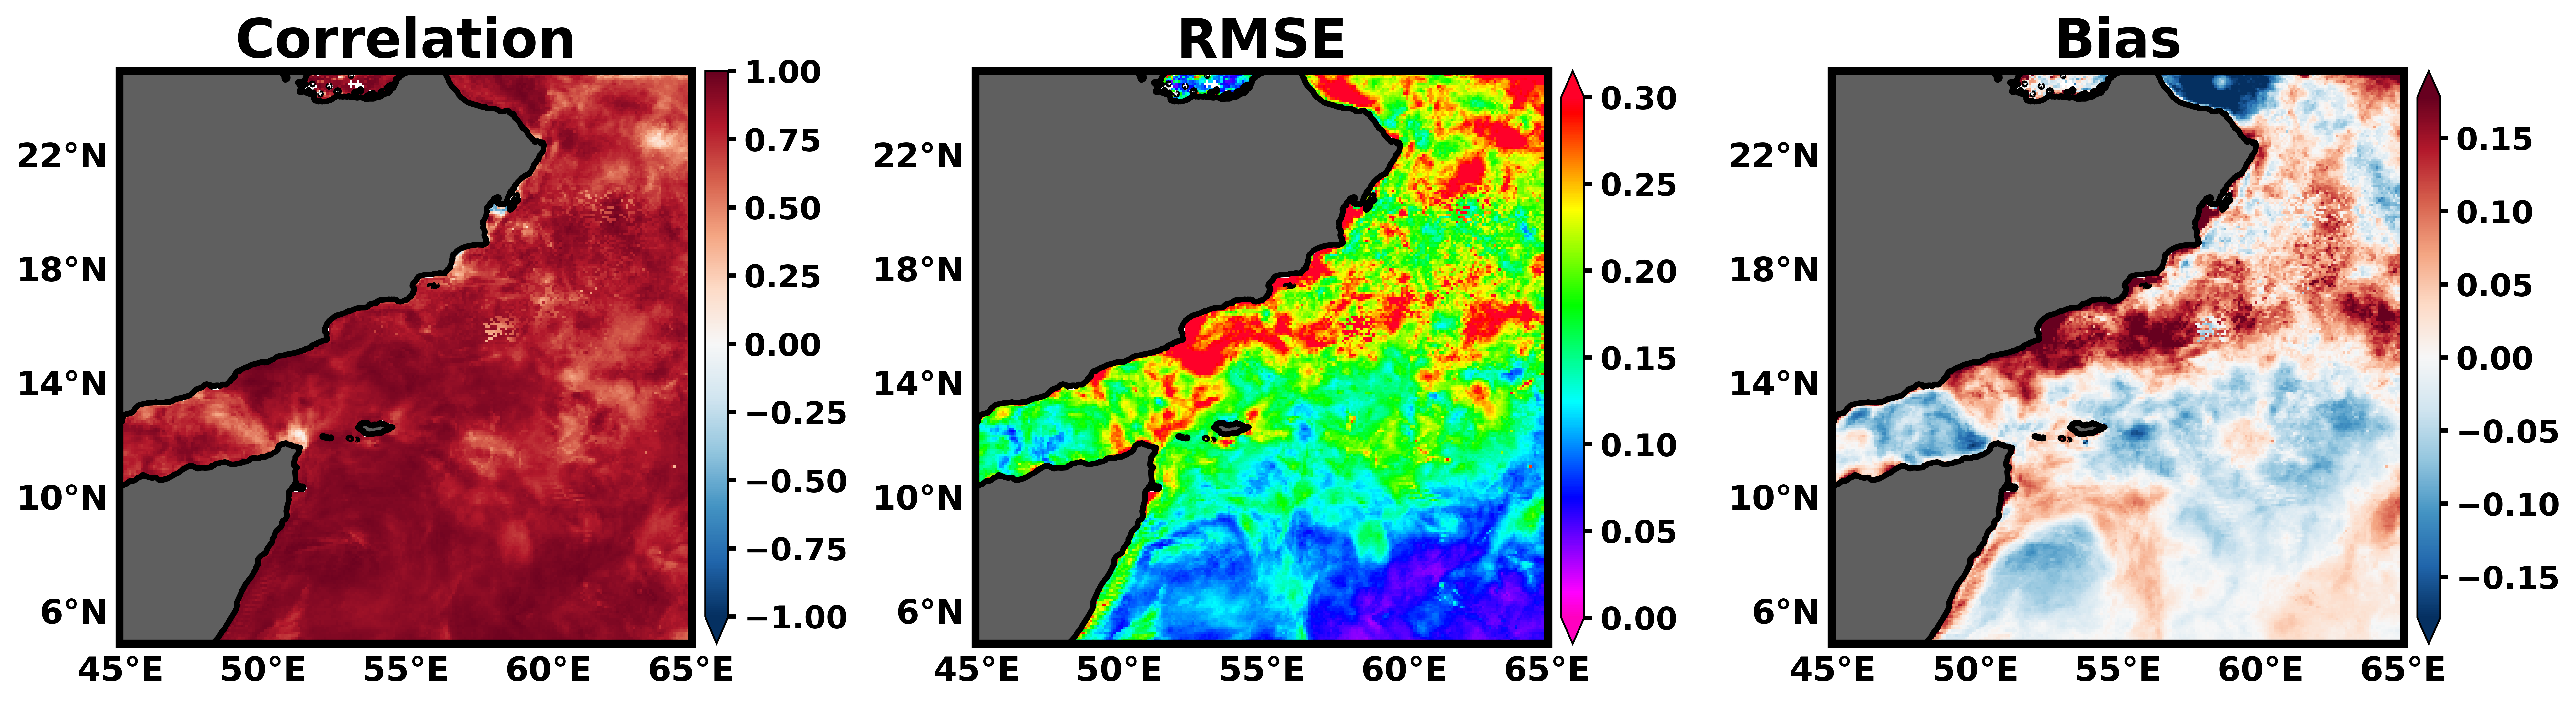

In [39]:
# logged

# ==========================================================
# Spatial Performance Maps
# Correlation | RMSE | Bias
# ==========================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xskillscore as xs
import matplotlib.ticker as mticker
# ==========================================================
# Compute Metrics
# ==========================================================


corr_map = xs.pearson_r(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

rmse_map = xs.rmse(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

bias_map = xs.me(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)



# ==========================================================
# Global Plot Settings
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Create Figure
# ==========================================================

fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(16,16),
    dpi=500,
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# ==========================================================
# Correlation Map
# ==========================================================

corr_plot = corr_map.plot(
    ax=ax[0],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    robust=True,
    add_colorbar=False,
    
)
divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes(
    "right",
    size="4%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar0 = fig.colorbar(
    corr_plot,
    cax=cax0,
    extend="min"
    #ticks=[0.6, 0.70, 0.80, 0.9, 1.0]
    
)




ax[0].set_title(
    "Correlation",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# RMSE Map
# ==========================================================

rmse_plot = rmse_map.plot(
    ax=ax[1],
    transform=ccrs.PlateCarree(),
    cmap="gist_rainbow_r",          
    vmin=0.0,
    vmax=0.30,
    add_colorbar=False,
    
)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes(
    "right",
    size="4%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar1 = fig.colorbar(
    rmse_plot,
    cax=cax1,
    extend="both"
    #ticks=[0, 0.1, 0.2, 0.3]
)



ax[1].set_title(
    "RMSE",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# Bias Map
# ==========================================================

bias_plot = bias_map.plot(
    ax=ax[2],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    center=0,
    robust=True,
    add_colorbar=False,
    
)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes(
    "right",
    size="4%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar2 = fig.colorbar(
    bias_plot,
    cax=cax2,
    extend="both"
)

ax[2].set_title(
    "Bias",
    fontsize=24,
    fontweight="bold"
)

# ==========================================================
# Coastlines, Land, Gridlines, Tick Styling
# ==========================================================

for a in ax:

    # --------------------------------------
    # Grey Land
    # --------------------------------------

    a.add_feature(
        cfeature.LAND,
        facecolor="#5f5f5f",
        edgecolor="none",
        zorder=0
    )

    # --------------------------------------
    # Black Coastlines
    # --------------------------------------

    a.coastlines(
        resolution="10m",
        color="black",
        linewidth=2.5
    )
    
    # Bold subplot boundary
    for spine in a.spines.values():
        spine.set_linewidth(3.5)
        spine.set_edgecolor("black")
    
    

    # --------------------------------------
    # Latitude / Longitude Labels
    # --------------------------------------

    gl = a.gridlines(
        draw_labels=True,
        linewidth=0.0,
        linestyle="--",
        alpha=0.5
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 15,
        "weight": "bold"
    }

    
    
    
    

    gl.xlocator = mticker.FixedLocator(np.arange(45, 66, 5))   # 45°E to 80°E every 5°
    gl.ylocator = mticker.FixedLocator(np.arange(6, 29, 4))
    
    gl.ylabel_style = {
        "size": 15,
        "weight": "bold"
    }

    # --------------------------------------
    # Bold Tick Labels
    # --------------------------------------

    for label in a.get_xticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(15)

    for label in a.get_yticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(15)

# ==========================================================
# Make Colorbar Tick Labels Bold
# ==========================================================

for cbar in [cbar0, cbar1, cbar2]:

    cbar.ax.tick_params(
        labelsize=14,
        width=2.0
    )

    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight("bold")

# ==========================================================
# Layout
# ==========================================================

plt.tight_layout()

plt.show()

In [40]:
print(rmse_map.mean())
print(corr_map.mean())
print(bias_map.mean())

<xarray.DataArray ()> Size: 4B
array(0.17289723, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(0.82494444, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(0.0131195, dtype=float32)


In [41]:
RMSE : 0.16351
Corr : 0.8441
Bias : -0.0074

/tmp/ipykernel_485299/799931716.py:271: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


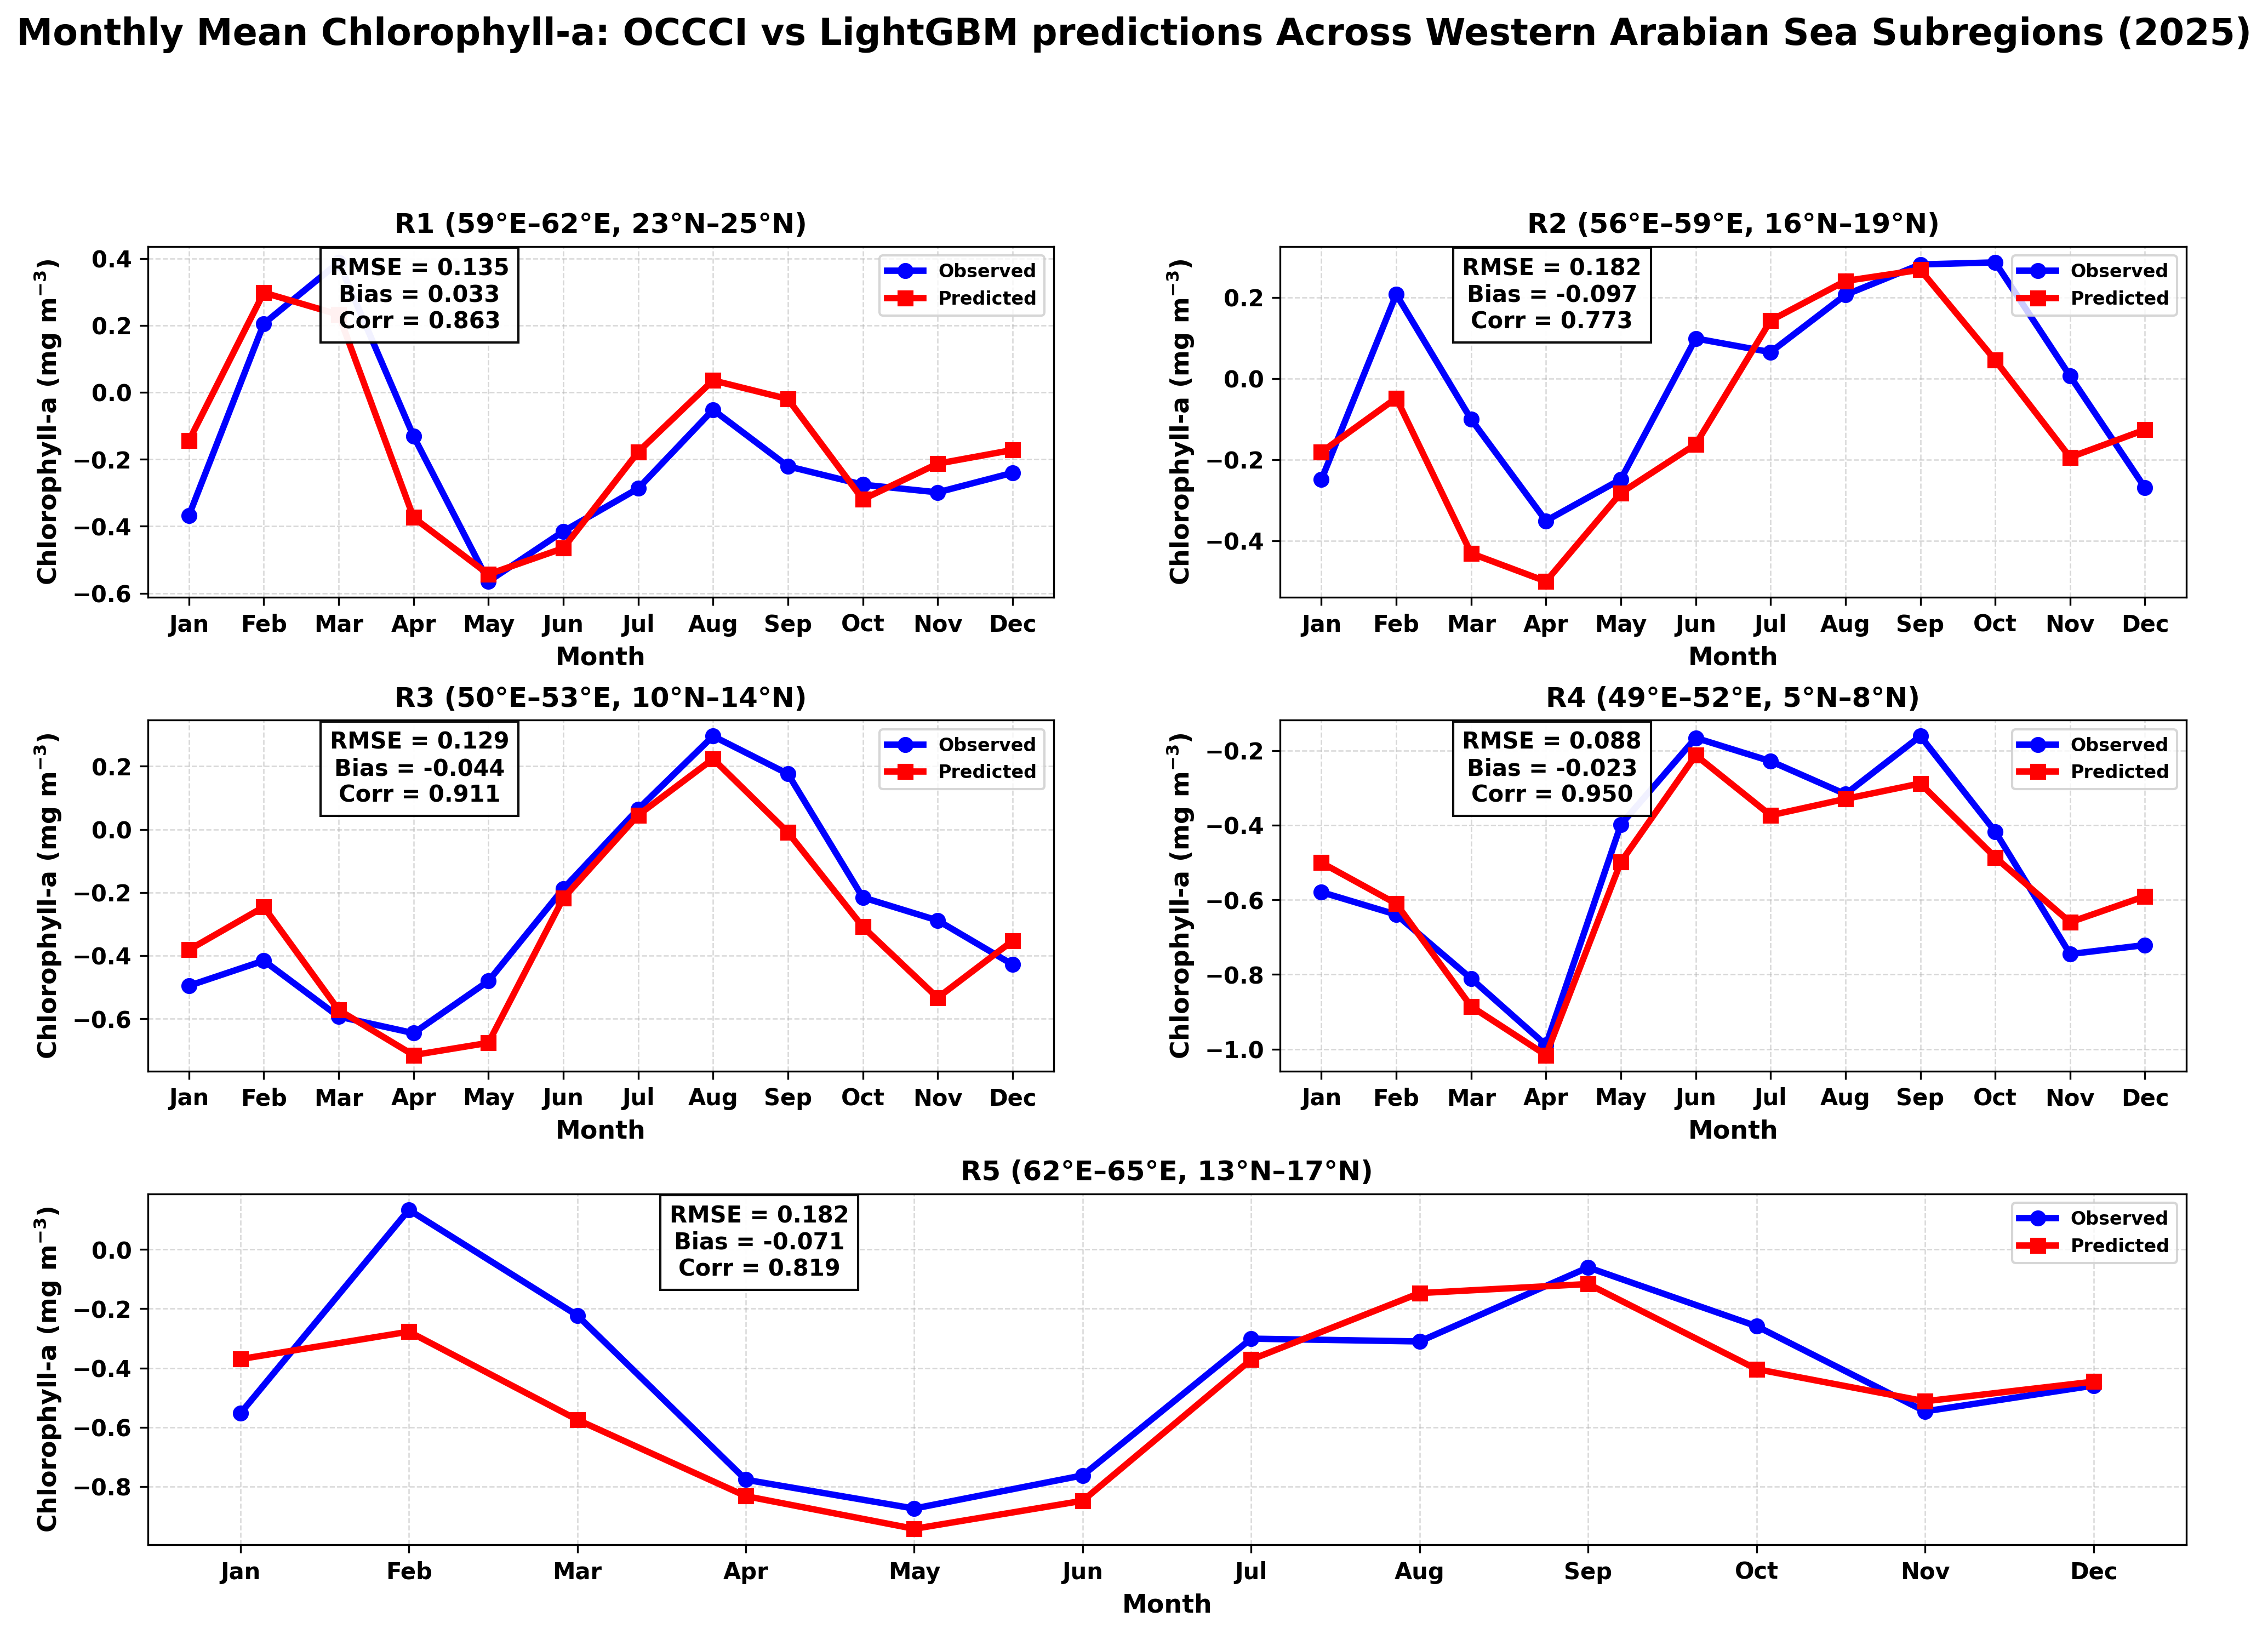

In [42]:

# ==========================================================
# Regional Monthly Chl-a Comparison
# Layout:
#
# R1   R2
# R3   R4
# R5   R6
#    R7
#
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

# ==========================================================
# Subregions
# ==========================================================


regions = {

    "R1 (59°E–62°E, 23°N–25°N)":
        [59.0, 62.0, 23.0, 25.0],

    "R2 (56°E–59°E, 16°N–19°N)":
        [56.0, 59.0, 16.0, 19.0],

    "R3 (50°E–53°E, 10°N–14°N)":
        [50.0, 53.0, 10.0, 14.0],

    "R4 (49°E–52°E, 5°N–8°N)":
        [49.0, 52.0, 5.0, 8.0],

    "R5 (62°E–65°E, 13°N–17°N)":
        [62.0, 65.0, 13.0, 17.0]
}
# ==========================================================
# Month Labels
# ==========================================================

months = [
    "Jan","Feb","Mar","Apr",
    "May","Jun","Jul","Aug",
    "Sep","Oct","Nov","Dec"
]

# ==========================================================
# Create Figure Layout
# ==========================================================

fig = plt.figure(
    figsize=(16, 14),
    dpi=300
)

gs = fig.add_gridspec(
    4, 2,
    hspace=0.35,
    wspace=0.25
)

axes = [
    fig.add_subplot(gs[0, 0]),  # R1
    fig.add_subplot(gs[0, 1]),  # R2
    fig.add_subplot(gs[1, 0]),  # R3
    fig.add_subplot(gs[1, 1]),  # R4
    fig.add_subplot(gs[2, :]),  # R5 
   
    
]

# ==========================================================
# Loop Through Regions
# ==========================================================

for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Regional subset
    # ------------------------------------------------------

    ds_reg = ds_2025.sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Monthly Regional Means
    # ------------------------------------------------------

    obs_monthly = np.log10(
        ds_reg["chlor_a"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    pred_monthly = np.log10(
        ds_reg["chlor_a_pred"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    valid = (
        np.isfinite(obs_monthly)
        &
        np.isfinite(pred_monthly)
    )

    obs_valid = obs_monthly[valid]
    pred_valid = pred_monthly[valid]

    rmse = np.sqrt(
        mean_squared_error(
            obs_valid,
            pred_valid
        )
    )

    bias = np.mean(
        pred_valid - obs_valid
    )

    corr = np.corrcoef(
        obs_valid,
        pred_valid
    )[0, 1]

    # ------------------------------------------------------
    # Observed
    # ------------------------------------------------------

    ax.plot(
        months,
        obs_monthly,
        color="blue",
        linewidth=2.8,
        marker="o",
        markersize=6,
        label="Observed"
    )

    # ------------------------------------------------------
    # Predicted
    # ------------------------------------------------------

    ax.plot(
        months,
        pred_monthly,
        color="red",
        linewidth=2.8,
        marker="s",
        markersize=6,
        label="Predicted"
    )

    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    metric_text = (
        f"RMSE = {rmse:.3f}\n"
        f"Bias = {bias:.3f}\n"
        f"Corr = {corr:.3f}"
    )

    ax.text(
        0.30,
        0.97,
        metric_text,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        va="top",
        ha="center",
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )

    # ------------------------------------------------------
    # Titles
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=12,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------

    ax.set_xlabel(
        "Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"Chlorophyll-a (mg m$^{-3}$)",
        fontsize=11,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Grid
    # ------------------------------------------------------

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.5
    )

    # ------------------------------------------------------
    # Tick Formatting
    # ------------------------------------------------------

    ax.tick_params(
        axis='both',
        labelsize=10
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # ------------------------------------------------------
    # Legend
    # ------------------------------------------------------

    ax.legend(
        loc="upper right",
        prop={
            "weight": "bold",
            "size": 8
        }
    )

# ==========================================================
# Global Figure Title
# ==========================================================

fig.suptitle(
    #"logged space",
    "Monthly Mean Chlorophyll-a: OCCCI vs LightGBM predictions Across Western Arabian Sea Subregions (2025)",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()